# Pattern Recognition 2 - Feature Space

**Objectives**

* Compute distances between objects in feature space
* Use PCA to perform reduce the dimensionality of the problem
* Implement face recognition using [Eigenfaces](http://en.wikipedia.org/wiki/Eigenface)

## Feature space distance

The `ocr_features.npy` file contains extracted features for each letter from the document used in the previous lab, and the `ocr_class.npy` file contains the character corresponding to these features.

The 18 features, extracted with the `regionprops` methods from `scikit-image` are, in order: 


> area, convex area, eccentricity, equivalent diameter, extent, filled area, intertia tensor eigenvalue 1, inertia tensor eigenvalue 2, major axis length, minor axis length, Hu moment 1, Hu moment 2, Hu moment 3, Hu moment 4, Hu moment 5, Hu moment 6, perimeter, solidity

* Create a method which computes the Euclidian distance, in feature space, between two objects.
* Check if the "nearest" object is of the same class.
* What can you do to improve this "distance-based" classification? 

In [14]:
import numpy as np

ocr_features = np.load('../data/ocr_features.npy')
ocr_class = np.load('../data/ocr_class.npy')

print(ocr_features.shape)
print(np.unique(ocr_class))

(2392, 18)
['0' '1' '4' '5' 'A' 'B' 'C' 'D' 'F' 'G' 'I' 'L' 'M' 'N' 'O' 'R' 'S' 'T'
 'W' 'a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i' 'k' 'l' 'm' 'n' 'o' 'p' 'q' 'r'
 's' 't' 'u' 'v' 'w' 'x' 'y' 'z']


## Eigenfaces

The `faces.npy` file contains a 3D matrix containing 2963 images, each with 170x200 pixels, encoded in 8-bit grayscale.

In [15]:
from matplotlib import pyplot as plt
%matplotlib inline

faces = np.load('../data/faces.npy', allow_pickle=True)
print(faces.shape, faces.dtype, faces.min(), faces.max())

(2963, 200, 170) uint8 0 255


/var/folders/dm/7w0jh4z92gb722hmvw9k3qc00000gn/T/ipykernel_58778/1826463895.py:4: UserWarning: Reading `.npy` or `.npz` file required additional header parsing as it was created on Python 2. Save the file again to speed up loading and avoid this warning.
  faces = np.load('../data/faces.npy', allow_pickle=True)


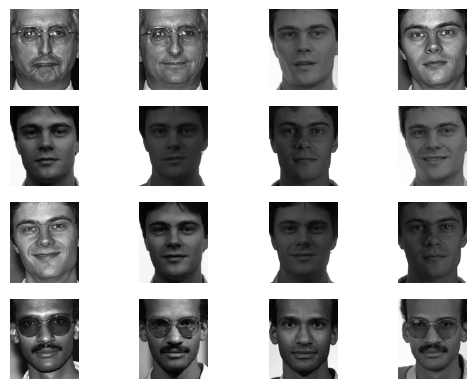

In [16]:
# Show some faces:
plt.figure()
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(faces[i], cmap=plt.cm.gray)
    plt.axis('off')
plt.show()

In [17]:
# Example of eigen value extraction
import numpy as np
from numpy import linalg as LA

w,v = LA.eig(np.diag((1, 2, 3)))
print(w,v)

[1. 2. 3.] [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


(200, 170)


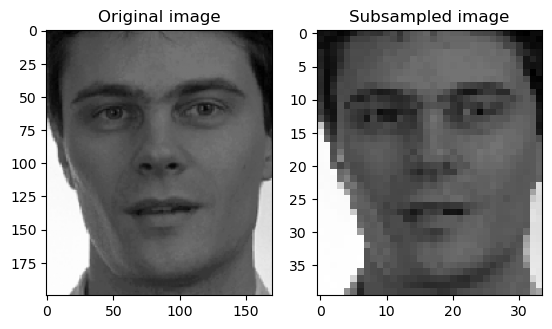

In [18]:
# Example of subsampling
im = faces[2]
print(im.shape)
plt.figure()
plt.subplot(1,2,1)
plt.imshow(im, cmap=plt.cm.gray)
plt.title("Original image")
plt.subplot(1,2,2)
plt.imshow(im[::5,::5], cmap=plt.cm.gray)
plt.title("Subsampled image")
plt.show()


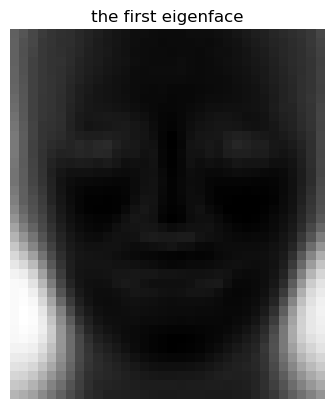

In [19]:
# we need to recover every sumpled image 

faces_sub = faces[:, ::5, ::5] 


# we need to store the shape of the subsampled images for later use
n_images, h, w = faces_sub.shape 

# conversion to 2D matrix where each row is a flattened image
T = faces_sub.reshape(n_images, h * w) 

# reducing that with this reshape, we got a matrix T with image as first coord and the second coord that are all of pixels flattened

# 2. Zero-center T
T_mean = np.mean(T, axis=0)
# subctract the mean from each row (each image)
T_centered = T - T_mean

# compute the covariance matrix (scatter matrix)
S = T_centered.T @ T_centered

# eigen decomposition of the scatter matrix
eigvals, eigvecs = np.linalg.eig(S) 

# take only the real part of the eigenvectors (in case of numerical issues)
eigvecs = np.real(eigvecs)

# visualize the first eigenface (the one with the highest eigenvalue)
prima_eigenface_1d = eigvecs[:, 0]

# each column of eigvecs is an eigenface does not rapresent the face of a person 

# reconvert the 1D eigenface back to 2D for visualization
prima_eigenface_2d = prima_eigenface_1d.reshape(h, w)

plt.figure()
plt.imshow(prima_eigenface_2d, cmap=plt.cm.gray) 
plt.title("the first eigenface")
plt.axis('off')
plt.show()

### Compression

1. Reconstruct images using only the first N eigenfaces (e.g. N=100).
2. Compare (visually) reconstructed images with original images

### Direct approach

1. Write a program that subsample the images (e.g. by 5), converts 2D images into lines, and collect all these lines into one single matrix **T**.
1. Zero-center **T** by removing the "mean image" ($T_i \leftarrow T_i - T_{mean}$)
1. Compute the variance/covariance matrix of **T**:
$$ \mathbf{S} = \mathbf{T^TT}$$
1. Compute the eigenvalues $\lambda_i$ and eigenvectors $\mathbf{v}_i$ of **S**
$$\mathbf{Sv}_i = \mathbf{T^T}\mathbf{Tv}_i = \lambda_i \mathbf{v}_i$$
1. The eigenvectors have the same size as the images, and are often referred to as "eigenfaces". Display some of them.

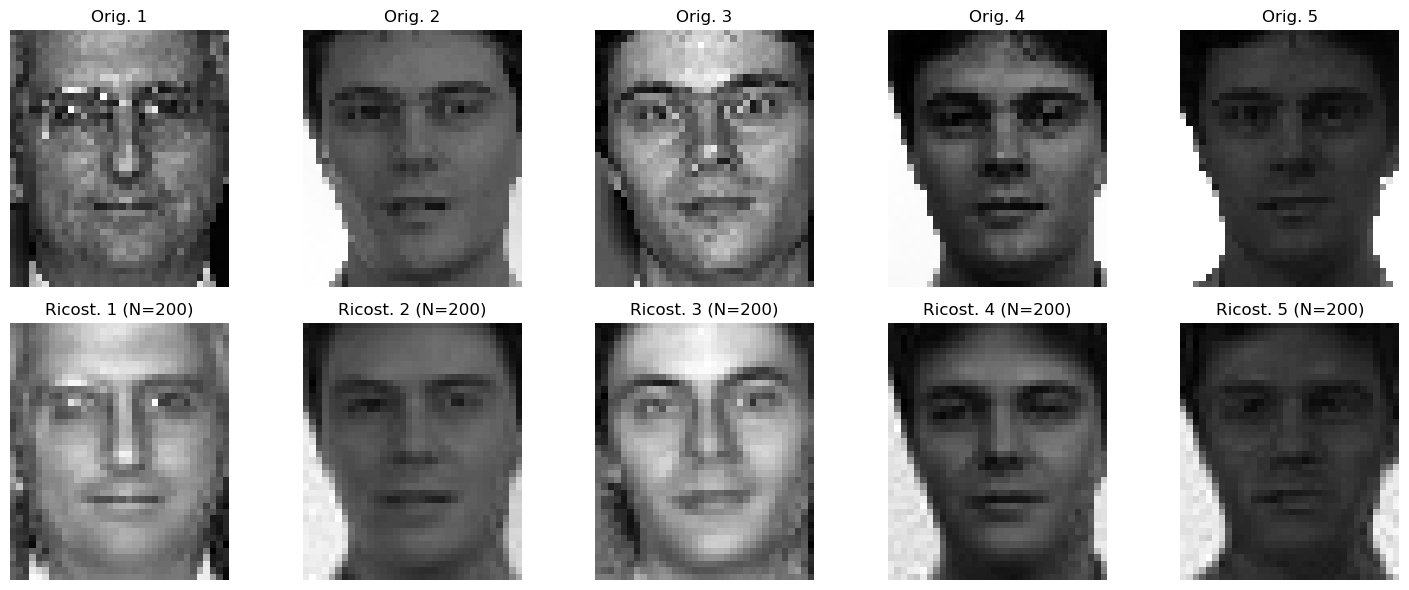

In [20]:
# here we are going to select the firs N eigenfaces
n_components = 200


U_k = np.real(eigvecs[:, :n_components]) 

# with this we have the first N eigenfaces as columns of U_k
weights = T_centered @ U_k 

# Recostruction
# we need to use the weights obtained from the projection to reconstruct the images
T_reconstructed_centered = weights @ U_k.T 

# we need to add the mean face (T_mean) that we had subtracted in step 2 of the previous cell to get the final reconstructed images
T_reconstructed = T_reconstructed_centered + T_mean

# select what image we want to visualize
img_idx = 12


# number of faces to visualize
num_faces = 5 

fig, axes = plt.subplots(2, num_faces, figsize=(15, 6))

for i in range(num_faces):
    idx = i + 1
    
    img_original = T[idx].reshape(h, w)
    img_recon = T_reconstructed[idx].reshape(h, w)
    
    axes[0, i].imshow(img_original, cmap=plt.cm.gray)
    axes[0, i].set_title(f"Orig. {idx}")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(img_recon, cmap=plt.cm.gray)
    axes[1, i].set_title(f"Ricost. {idx} (N={n_components})")
    axes[1, i].axis('off')

plt.tight_layout() 
plt.show()

### Face recognition

1. Using the simplified vector space (e.g. 100 first eigenfaces), compute the euclidian distance between one face and the others.
2. For a subset of the image of the database, find the 4 closest matches.

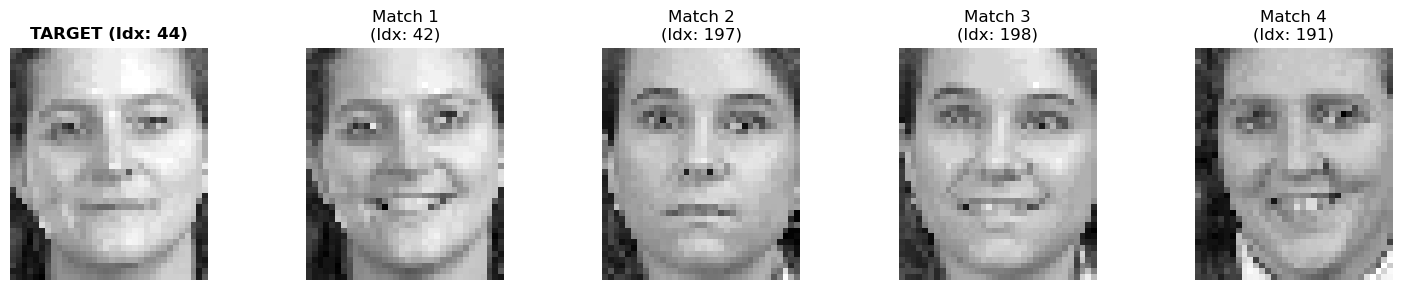

In [21]:
import numpy as np
import matplotlib.pyplot as plt


target_ids = [44] # target that we want to visualize
num_matches = 4   # closest matches to the target

num_targets = len(target_ids)
fig, axes = plt.subplots(nrows=num_targets, ncols=num_matches + 1, 
                         figsize=(15, 3 * num_targets))

if num_targets == 1:
    axes = np.expand_dims(axes, axis=0)

# Iterable calculation and plot
for row, target_idx in enumerate(target_ids):
    
    # Recover of real weights of the target
    w_target = weights[target_idx] 
    
    # Eunclidean distance between target and candidate
    distances = np.sum(
        np.square(w_target - weights),
        axis=1,
    )
    
    # sorting of points
    sorted_indices = np.argsort(distances)
    closest_matches_indices = sorted_indices[1:num_matches + 1]
    
    # plotting of the target
    axes[row, 0].imshow(T[target_idx].reshape(h, w), cmap=plt.cm.gray)
    axes[row, 0].set_title(f"TARGET (Idx: {target_idx})", fontweight='bold')
    axes[row, 0].axis('off')
    
    # plotting of closest points founded
    for col, match_idx in enumerate(closest_matches_indices, start=1):
        
        axes[row, col].imshow(T[match_idx].reshape(h, w), cmap=plt.cm.gray)
        
        match_dist = distances[match_idx]
        axes[row, col].set_title(f"Match {col}\n(Idx: {match_idx})")
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

### Indirect approach

Instead of using the eigenvalues/eigenvectors of $\mathbf{S} = \mathbf{T^TT}$, compute the the eigenvalues/eigenvectors of $\mathbf{Q} = \mathbf{TT^T}$.

Let $\mathbf{u_i}$ be the eigenvectors of $\mathbf{Q}$. We have:
$$\mathbf{TT^T}\mathbf{u}_i = \lambda_i \mathbf{u}_i$$

By multiplying to the left with $\mathbf{T^T}$, we have:
$$\mathbf{T^T}\mathbf{TT^T}\mathbf{u}_i = \lambda_i\mathbf{T^T}\mathbf{u}_i$$
$$\mathbf{S}\mathbf{T^T}\mathbf{u}_i = \lambda_i\mathbf{T^T}\mathbf{u}_i$$

Which means that if $\mathbf{u}_i$ is eigenvector of $\mathbf{Q}$, then $\mathbf{T^T}\mathbf{u}_i$ is eigenvector of $\mathbf{S}$.

The indirect approach thus becomes:
1. Compute the eigenvectors $\mathbf{u}_i$ of $\mathbf{Q} = \mathbf{TT^T}$.
1. Compute the eigenfaces with $\mathbf{v}_i = \mathbf{T^T}\mathbf{u}_i$ 
1. Reconstruct the images using only the first N eigenfaces (e.g. N=100)
1. Compare (visually) reconstructed images with original images
1. Use the indirect approach with more resolution (without subsampling the images)

Use this new feature space to perform the same face recognition method.

In [22]:
def indirect_approach():

    faces_sub = faces[:, :, :] 
    n_images, h, w = faces_sub.shape 
    T = faces_sub.reshape(n_images, h * w) 

    # 2. Zero-center
    T_mean = np.mean(T, axis=0)
    T_centered = T - T_mean


    Q = T_centered @ T_centered.T 

    eigvals, eigvecs = np.linalg.eig(Q)

    eigvals = np.real(eigvals)
    eigvecs = np.real(eigvecs)

    sort_indices = np.argsort(eigvals)[::-1] 
    eigvals = eigvals[sort_indices]
    eigvecs = eigvecs[:, sort_indices]

    eigenfaces = T_centered.T @ eigvecs
    
    eigenfaces = eigenfaces / np.linalg.norm(eigenfaces, axis=0)

    n_components = 100
    U_k = eigenfaces[:, :n_components] 

    weights = T_centered @ U_k 

    T_reconstructed_centered = weights @ U_k.T 
    T_reconstructed = T_reconstructed_centered + T_mean

    return T, T_reconstructed, weights, U_k

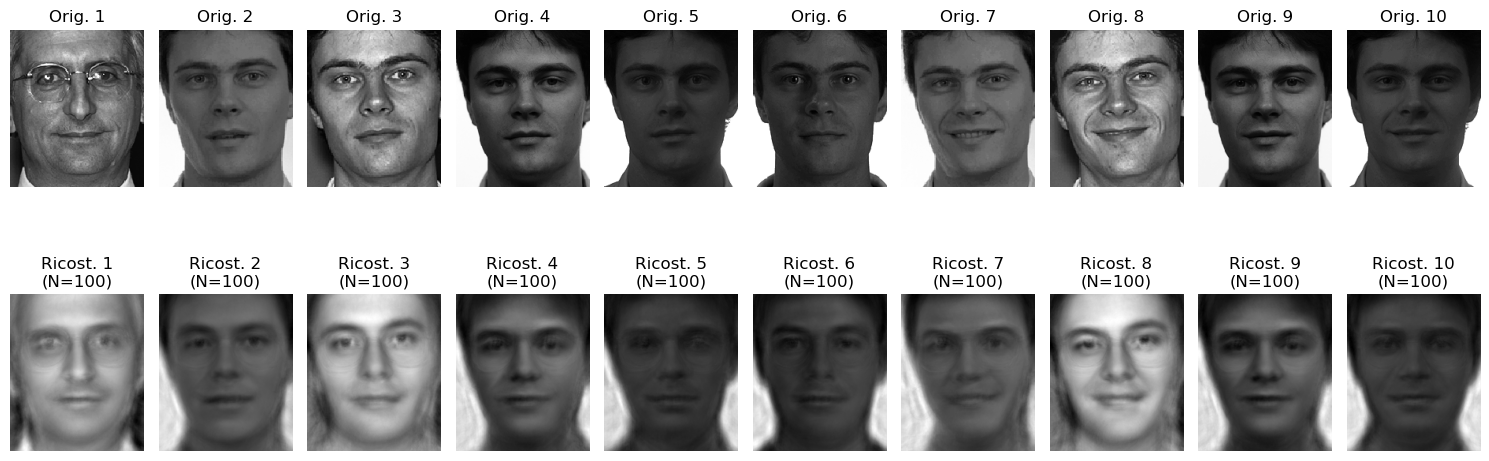

In [23]:
T, T_reconstructed, weights, U_k = indirect_approach()

h, w = 200, 170 

# we are taking the first n_eigenfaces
n_components = 100 

num_faces = 10

fig, axes = plt.subplots(2, num_faces, figsize=(15, 6))

for i in range(num_faces):
    idx = i + 1
    
    img_original = T[idx].reshape(h, w)
    img_recon = T_reconstructed[idx].reshape(h, w)

    axes[0, i].imshow(img_original, cmap=plt.cm.gray)
    axes[0, i].set_title(f"Orig. {idx}")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(img_recon, cmap=plt.cm.gray)
    axes[1, i].set_title(f"Ricost. {idx}\n(N={n_components})")
    axes[1, i].axis('off')

plt.tight_layout() 
plt.show()

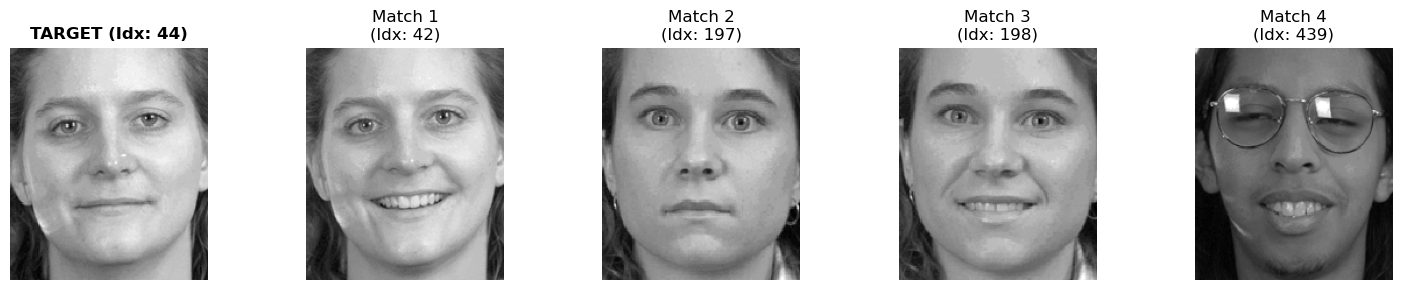

In [24]:
T, T_reconstructed, weights, U_k = indirect_approach()

h, w = 200, 170

target_ids = [44] # Example, what we want compare is the previous result using the direct approach
num_matches = 4 

num_targets = len(target_ids)
fig, axes = plt.subplots(nrows=num_targets, ncols=num_matches + 1, 
                         figsize=(15, 3 * num_targets))

if num_targets == 1:
    axes = np.expand_dims(axes, axis=0)

for row, target_idx in enumerate(target_ids):
    
    w_target = weights[target_idx] 
    
    distances = np.sum(
        np.square(w_target - weights),
        axis=1,
    )
    
    sorted_indices = np.argsort(distances)
    closest_matches_indices = sorted_indices[1:num_matches + 1]
    
    axes[row, 0].imshow(T[target_idx].reshape(h, w), cmap=plt.cm.gray)
    axes[row, 0].set_title(f"TARGET (Idx: {target_idx})", fontweight='bold')
    axes[row, 0].axis('off')
    
    for col, match_idx in enumerate(closest_matches_indices, start=1):
        
        axes[row, col].imshow(T[match_idx].reshape(h, w), cmap=plt.cm.gray)
        
        match_dist = distances[match_idx]
        axes[row, col].set_title(f"Match {col}\n(Idx: {match_idx})")
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()